In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/9/2022
# version ='1.0'

### Demo: An Experiment on Affine Invariance in Newton's Method

In the text book {book-convex-2004}, section 9.5, 'Newton's method', the affine invariance of Netwon's method was discussed.  As an example, a family of problem indexed by the parameters $\gamma$ was studied. In this demo, an experiment is implemented in python to demonstrate such affine invariance in Newton's method.

The minimization problem is

$$
\bar{f}(\bar{x})=c^TT\bar{x}-\displaystyle{\sum_{i=1}^{m}}\log(b_i-a_i^TT\bar{x})
$$

where, $x\in R^n, n=100, m = 500$. 
$$
T = \mathbf{diag}((1, \gamma^{1/n}, \gamma^{2/n}, ..., \gamma^{(n-1)/n})) + E_{\delta}
$$

where $E_{\delta}$ is a matrix with random coefficients $e_{i,j}$, and $e_{i,j}\in(0, \delta)$. $E_{\delta}$ is considered as noise.

In the implementation of the Newton's method, the gradient and the hessian of $\bar{f}(\bar{x})$ is

$$
\begin{array}{rcl}
\nabla \bar{f}({\bar{x}}) & = & T^T \left(c + A^T(\dfrac{1}{b-AT\bar{x}})\right) \\
\nabla^2\bar{f}({\bar{x}}) & = & T^T A^T(\dfrac{1}{b-AT\bar{x}})AT
\end{array}
$$

In the experiment, $\gamma = 10^{-2 : 0.5 : 2}$. Backtracking line search is used with $\alpha=0.01, \beta=0.5$.

In the first experiment result, the affine invariance of the Newton's method is clearly visualized.

More details on the setup of the demo in Jupiter notebook for practice can be accessed from the Lecture's JupyterLab webpage:

[JupyterLab webpage](https://wuzhuchun.club:9091/lab/tree/welcome.ipynb}{https://wuzhuchun.club:9091/lab/tree/welcome.ipynb).


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

In [3]:
def my_f_fesasible(x, c, b, A, T):
    return np.all(b - A @ (T @ x) > 0)


def my_f(x, c, b, A, T):
    return (c.T @ (T @ x) - np.sum(np.log(b - A @ (T @ x)))).item()


def my_gradient_f(x, c, b, A, T):
    return (T.T @ c) + T.T @ (A.T @ (1 / (b - A @ (T @ x))))


def my_hessian_f(x, c, b, A, T):
    diag = np.diag(np.squeeze(1 / ((b - A @ (T @ x)) ** 2)))
    hessian = T.T @ (A.T @ diag @ A) @ T
    return hessian

In [4]:
def my_newton_step_decrement(x, args):
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    hessian_inv = np.linalg.inv(hessian)
    x_nt = -1 * hessian_inv @ gradient
    decrement = -1 * gradient.T @ x_nt
    return x_nt, decrement.item()

In [5]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    t = 1
    while (not my_f_fesasible(x + delta_x * t, *args)) \
            or f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
        t = beta * t
    return t

In [6]:
def plot_convergence(m, n, gammas):
    np.random.seed(1)
    A = np.random.rand(m, n)

    if not np.linalg.matrix_rank(A) == n:
        raise RuntimeError("rank(A) should be equal to n!")

    Lambda = -1 * np.random.rand(m, 1)
    c = A.T @ Lambda
    inv_Lambda = 1 / Lambda
    b = -1 * inv_Lambda
    f_min = -np.sum(np.log(b)).item()

    args = (c, b, A)
    epsilon = 1e-10
    alpha = 0.01
    beta = 0.5

    for gamma in gammas:
        #print('Info: gamma={}'.format(gamma))
        sigma = 0.1
        T = np.diag(np.array([gamma ** (k * 1.0 / n) for k in range(n)])) + sigma * np.random.rand(n, n)

        args = (c, b, A, T)
        x0 = -1 * (np.linalg.inv(T) @ (np.ones([n, 1])))
        x = x0
        x_nt, decrement = my_newton_step_decrement(x, args)
        fx = [my_f(x, *args)]
        decrements = [decrement]
        iteration = 0
        while decrement / 2 > epsilon:
            #print('Info: [{}] decrement={}, fx={}'.format(iteration, decrement, fx[-1]))
            t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
            x_next = x + t * x_nt
            x = x_next
            x_nt, decrement = my_newton_step_decrement(x, args)
            fx.append(my_f(x, *args))
            decrements.append(decrement)
            iteration = iteration + 1

        ax = plt.subplot(1, 2, 1)
        ax.semilogy(np.array(fx) - f_min, marker='+', fillstyle='none', linestyle='dashed', label=r'$\gamma={:.3f}$'.format(gamma))
        ax2 = plt.subplot(1, 2, 2)
        ax2.semilogy(decrements, marker='+', fillstyle='none', linestyle='dashed',
                    label=r'$\gamma={:.3f}$'.format(gamma))

    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.grid()
    ax.legend()
    ax.set_xlabel(r'iteration')
    ax.set_title(r'$f(x)-p^*$')

    ax2.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax2.grid()
    ax2.legend()
    ax2.set_xlabel(r'iteration')
    ax2.set_title(r'Newton decrement $\lambda^2(x)$')

    plt.show()

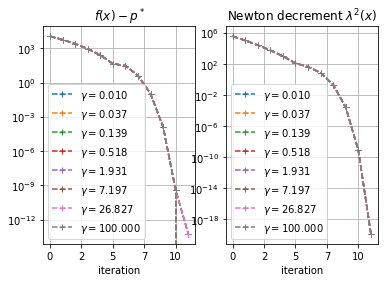

In [7]:
if __name__ == "__main__":
    gammas = 10 ** np.linspace(-2, 2, 8)
    plot_convergence(m=500, n=100, gammas=gammas)